# SPORA：哪些细胞类型能进入 Hist2Pheno 训练集

本笔记本从 `spora_CODEX_analysis.ipynb` 拆出，单独检查本机 `data/CODEX/spora` 的五个数据集。打印为中文。数据只读。

对照 Hoefflin 的 30 张大 mask 大约要几分钟。纳入结论和训练命令见 `spora_CellData.md`。训练脚本是 `run_spora_pancancer.sh`。


## 7. 哪些数据集的细胞类型能进入 Hist2Pheno 训练集

本段自包含，读本机 `data/CODEX/spora` 的五个数据集。数据只读。

Hist2Pheno 一条训练样本需要：配对且配准好的 H&E、细胞在 H&E 上的质心、能映射到现有泛癌 L2 的类型。没有 `metadata/cells.parquet` 表示标注缺失。hoefflin 的 30 张大 mask 对照大约要几分钟。

中文笔记：`spora_细胞类型_训练集纳入说明.md`。


数据根目录: /home/lingyu/ssd2/Python/Hist2Pheno/data/CODEX/spora
纳入训练集需要同时满足：有细胞类型、同一组织有配准好的 H&E、能得到 H&E 上的细胞质心、标签能落到现有泛癌 L2 且不属于 Unknown/杂类。

【haist2026lymph】头颈鳞癌淋巴结转移（Haist 2026, Cancer Cell）
  细胞类型表: 没有
  HE 组织 389（病人 79），CODEX 组织 389，1 µm H&E 图像 389
  1 µm 实例分割 0，virtues 分割 389，配准 {'exact': 778}

【hickey2023organization】人小肠组织图谱，非肿瘤（Hickey 2023）
  细胞类型表: 没有
  HE 组织 19（病人 3），CODEX 组织 64，1 µm H&E 图像 19
  1 µm 实例分割 64，virtues 分割 64，配准 {'no alignment': 45, 'exact': 38}

【hoefflin2026spatial】IDH 突变胶质瘤（Hoefflin 2026）
  细胞类型表: 有
  HE 组织 30（病人 25），CODEX 组织 30，1 µm H&E 图像 30
  1 µm 实例分割 30，virtues 分割 30，配准 {'exact': 60}
  标注细胞 2448212，标注组织 30，其中有 H&E 30，有分割 30
  标注组织配准 {'exact': 30}，重复 cell_id 0

【phillips2021immune】皮肤 T 细胞淋巴瘤 MF/SS（Phillips 2021）
  细胞类型表: 有
  HE 组织 70（病人 14），CODEX 组织 70，1 µm H&E 图像 70
  1 µm 实例分割 70，virtues 分割 70，配准 {'exact': 138, 'None': 2}
  标注细胞 117170，标注组织 69，其中有 H&E 69，有分割 69
  标注组织配准 {'exact': 69}，重复 cell_id 0

【schurch2020coordinated】结直肠癌 TMA（Schürch 2020, Cell）
  细胞类型表: 

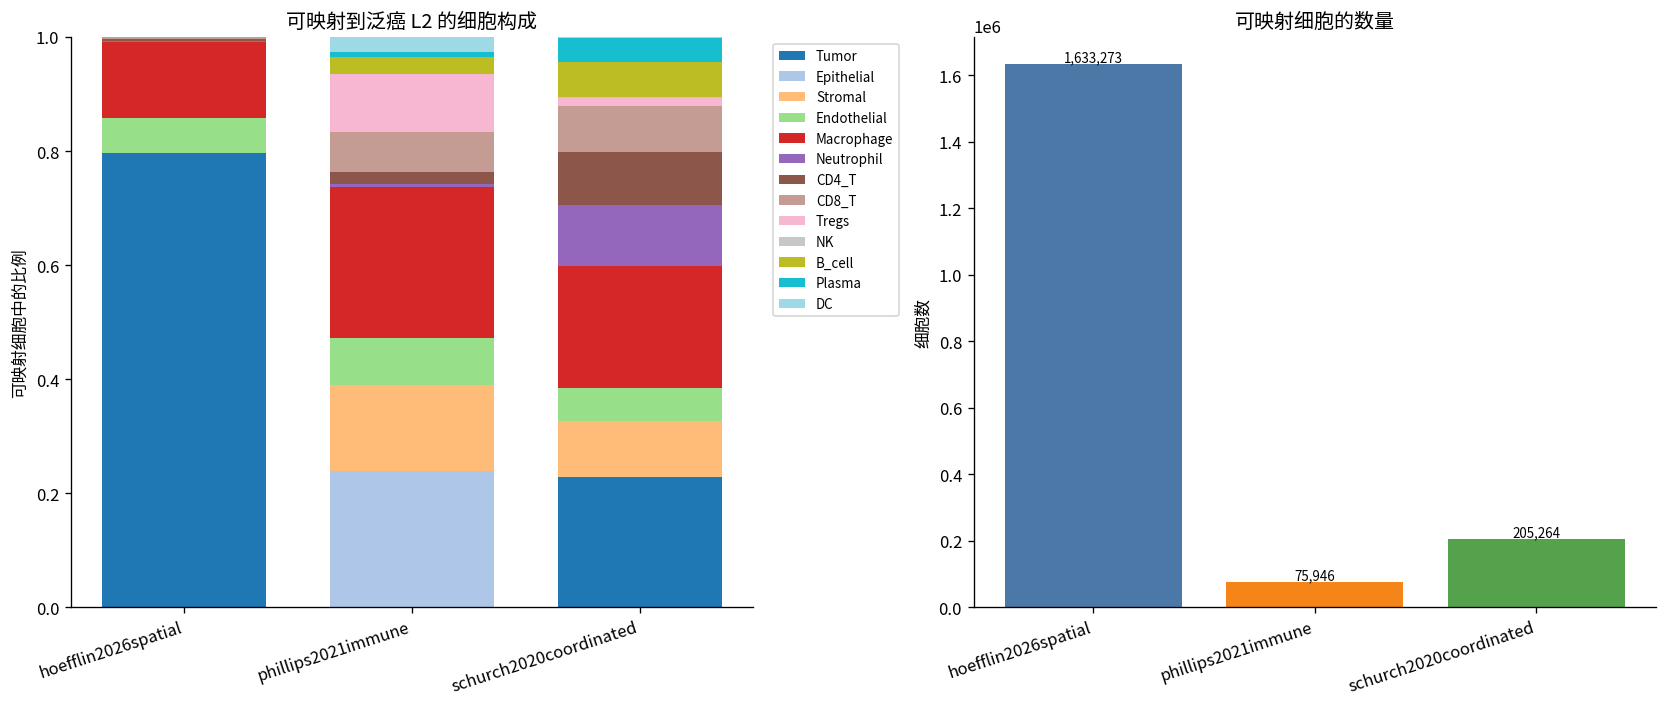

In [1]:
# 第 7 节自包含：不依赖前面单元格里的 lustre 路径。
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

DATA_ROOT = Path("/home/lingyu/ssd2/Python/Hist2Pheno/data/CODEX/spora")
OUT_DIR = Path("/home/lingyu/ssd2/Python/Hist2Pheno/code/spora/result")
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

_cjk_font = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
font_manager.fontManager.addfont(_cjk_font)
# 这个 TTC 注册出来的家族名是 Noto Sans CJK JP，字形里包含简体中文。
plt.rcParams["font.family"] = "Noto Sans CJK JP"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

DATASETS = [
    "haist2026lymph",
    "hickey2023organization",
    "hoefflin2026spatial",
    "phillips2021immune",
    "schurch2020coordinated",
]
DISEASE = {
    "haist2026lymph": "头颈鳞癌淋巴结转移（Haist 2026, Cancer Cell）",
    "hickey2023organization": "人小肠组织图谱，非肿瘤（Hickey 2023）",
    "hoefflin2026spatial": "IDH 突变胶质瘤（Hoefflin 2026）",
    "phillips2021immune": "皮肤 T 细胞淋巴瘤 MF/SS（Phillips 2021）",
    "schurch2020coordinated": "结直肠癌 TMA（Schürch 2020, Cell）",
}

# 提议映射到 Hist2Pheno celltype_pancancer 的 L2。
# None = 不进入训练集。这些原生名目前多半还不在 NATIVE_TO_V1，不能直接调用 native_to_pancancer。
# hoefflin 的 Oligo / Astro / Neuron 在原表 cell_type_atlas 里被标成 Unknown，这里跟随原表丢弃，不另立 Neural。
HOEFFLIN_L2 = {
    "cAC1": "Tumor", "cAC2": "Tumor", "cOPC": "Tumor", "cUndiff": "Tumor",
    "cMES": "Tumor", "cMESHyp": "Tumor",
    "Mac": "Macrophage", "Neutro": "Neutrophil", "Vasc": "Endothelial",
    "TcellCD4": "CD4_T", "TcellCD8": "CD8_T", "Bcell": "B_cell",
    "Oligo": None, "Astro": None, "Neuron": None, "low": None, "excluded": None,
}
# Phillips 的 tumor cells 是蕈样肉芽肿/Sézary 的恶性 T 细胞，形态不是泛癌 Tumor 的上皮性肿瘤，禁止映射到 Tumor。
PHILLIPS_L2 = {
    "CD4+ T cells": "CD4_T", "CD8+ T cells": "CD8_T", "Tregs": "Tregs",
    "B cells": "B_cell", "plasma cells": "Plasma",
    "DCs, CD11c+": "DC", "Langerhans cells": "DC",
    "macrophages (M1=M2)": "Macrophage", "macrophages (M1>M2)": "Macrophage",
    "macrophages (M2>M1)": "Macrophage",
    "neutrophils": "Neutrophil", "epithelium": "Epithelial",
    "stroma": "Stromal", "IDO+ stromal cells": "Stromal",
    "vasculature": "Endothelial", "lymphatics": "Endothelial",
    "tumor cells": None, "tumor cells, intraepithelial": None,
    "mast cells": None, "nerves": None, "CLA+ leukocytes": None,
}
SCHURCH_L2 = {
    "tumor cells": "Tumor",
    "CD4+ T cells": "CD4_T", "CD4+ T cells CD45RO+": "CD4_T", "CD4+ T cells GATA3+": "CD4_T",
    "CD8+ T cells": "CD8_T", "Tregs": "Tregs", "NK cells": "NK",
    "B cells": "B_cell", "plasma cells": "Plasma", "CD11c+ DCs": "DC",
    "CD68+CD163+ macrophages": "Macrophage", "CD68+ macrophages": "Macrophage",
    "CD11b+CD68+ macrophages": "Macrophage", "CD68+ macrophages GzmB+": "Macrophage",
    "CD163+ macrophages": "Macrophage", "CD11b+ monocytes": "Macrophage",
    "granulocytes": "Neutrophil", "stroma": "Stromal",
    "vasculature": "Endothelial", "lymphatics": "Endothelial",
    "smooth muscle": None, "adipocytes": None, "nerves": None,
    "immune cells": None, "immune cells / vasculature": None,
    "tumor cells / immune cells": None, "CD3+ T cells": None,
    "dirt": None, "undefined": None, "Unknown": None,
}
LABEL_COL = {
    "hoefflin2026spatial": "cell_type",
    "phillips2021immune": "old_cluster",
    "schurch2020coordinated": "cell_type",
}
LABEL_MAP = {
    "hoefflin2026spatial": HOEFFLIN_L2,
    "phillips2021immune": PHILLIPS_L2,
    "schurch2020coordinated": SCHURCH_L2,
}


def image_ids(base: Path, kind: str, res: str) -> set[str]:
    folder = base / kind / res / "images"
    if not folder.is_dir():
        return set()
    return {p.name.removesuffix(".ome.zarr") for p in folder.iterdir() if p.name.endswith(".ome.zarr")}


def mask_ids(base: Path) -> set[str]:
    folder = base / "segmentations" / "1_0mpp" / "cell_masks" / "instances"
    if not folder.is_dir():
        return set()
    return {p.name.removesuffix(".npz") for p in folder.glob("*.npz")}


print("数据根目录:", DATA_ROOT)
print("纳入训练集需要同时满足：有细胞类型、同一组织有配准好的 H&E、能得到 H&E 上的细胞质心、标签能落到现有泛癌 L2 且不属于 Unknown/杂类。")
print()

gate_rows = []
loaded = {}
for name in DATASETS:
    base = DATA_ROOT / name / name
    tissues = pd.read_parquet(base / "metadata" / "tissues.parquet")
    he = tissues[tissues.modality == "he"].drop_duplicates("tissue_id")
    codex = tissues[tissues.modality == "codex"].drop_duplicates("tissue_id")
    cells_path = base / "metadata" / "cells.parquet"
    he_img = image_ids(base, "he", "1_0mpp")
    masks = mask_ids(base)
    virtues = base / "segmentations" / "1_0mpp" / "cell_masks" / "instances_virtues"
    n_virtues = len(list(virtues.glob("*.npz"))) if virtues.is_dir() else 0
    row = {
        "数据集": name,
        "疾病": DISEASE[name],
        "病人数_HE": int(he.patient_id.nunique()),
        "HE组织数": int(he.tissue_id.nunique()),
        "CODEX组织数": int(codex.tissue_id.nunique()),
        "HE图像_1um": len(he_img),
        "实例分割_1um": len(masks),
        "virtues分割": n_virtues,
        "配准": tissues.alignment.astype(str).value_counts().to_dict(),
        "有细胞类型表": cells_path.exists(),
    }
    if cells_path.exists():
        cells = pd.read_parquet(cells_path)
        ann = set(cells.tissue_id.unique())
        he_meta = he[["tissue_id", "patient_id", "split"]].drop_duplicates("tissue_id")
        merged = cells.merge(he_meta, on="tissue_id", how="left", suffixes=("", "_he"))
        if "patient_id_he" in merged.columns:
            merged["patient_id"] = merged["patient_id"].fillna(merged["patient_id_he"])
        if "split_he" in merged.columns:
            merged["split"] = merged["split_he"]
        row.update({
            "标注细胞数": int(len(cells)),
            "标注组织数": int(len(ann)),
            "标注且有HE图像": int(len(ann & he_img)),
            "标注且有实例分割": int(len(ann & masks)),
            "细胞ID重复": int(cells.duplicated(["tissue_id", "cell_id"]).sum()),
            "标注组织配准": tissues[tissues.tissue_id.isin(ann)].drop_duplicates("tissue_id").alignment.astype(str).value_counts().to_dict(),
        })
        loaded[name] = merged
    else:
        row.update({
            "标注细胞数": 0,
            "标注组织数": 0,
            "标注且有HE图像": 0,
            "标注且有实例分割": 0,
            "细胞ID重复": 0,
            "标注组织配准": {},
        })
    gate_rows.append(row)
    print(f"【{name}】{DISEASE[name]}")
    print(f"  细胞类型表: {'有' if row['有细胞类型表'] else '没有'}")
    print(f"  HE 组织 {row['HE组织数']}（病人 {row['病人数_HE']}），CODEX 组织 {row['CODEX组织数']}，1 µm H&E 图像 {row['HE图像_1um']}")
    print(f"  1 µm 实例分割 {row['实例分割_1um']}，virtues 分割 {row['virtues分割']}，配准 {row['配准']}")
    if row["有细胞类型表"]:
        print(f"  标注细胞 {row['标注细胞数']}，标注组织 {row['标注组织数']}，其中有 H&E {row['标注且有HE图像']}，有分割 {row['标注且有实例分割']}")
        print(f"  标注组织配准 {row['标注组织配准']}，重复 cell_id {row['细胞ID重复']}")
    print()

gate = pd.DataFrame(gate_rows)
gate.to_csv(OUT_DIR / "spora_training_gate.csv", index=False)
print("门槛表已写入", OUT_DIR / "spora_training_gate.csv")

# Phillips：X/Y 在 0.37744 µm/像素 上；核对实例编号覆盖率。
phil_cells = loaded["phillips2021immune"]
phil_base = DATA_ROOT / "phillips2021immune" / "phillips2021immune"
in_mask = 0
for tissue, group in phil_cells.groupby("tissue_id"):
    ids = set(group.cell_id.astype(int))
    with np.load(phil_base / "segmentations" / "1_0mpp" / "cell_masks" / "instances" / f"{tissue}.npz", allow_pickle=False) as handle:
        present = set(np.unique(handle["mask"]).tolist()) - {0}
    in_mask += len(ids & present)
print("【phillips 坐标】")
print(f"  细胞表自带 X/Y。X {int(phil_cells.X.min())}–{int(phil_cells.X.max())}，Y {int(phil_cells.Y.min())}–{int(phil_cells.Y.max())}")
print(f"  表内 height×width 恒为 {int(phil_cells.height.iloc[0])}×{int(phil_cells.width.iloc[0])}，he_mpp={float(phil_cells.he_mpp.iloc[0])}")
print("  因此 X/Y 在 0.37744 µm/像素图像上。换到 1 µm/像素时乘以 0.37744。")
print(f"  1 µm 实例分割盖住 {in_mask}/{len(phil_cells)} 个细胞（{100 * in_mask / len(phil_cells):.1f}%）。没进 mask 的细胞仍可用 X/Y。")
missing_phil = sorted(set(pd.read_parquet(phil_base / "metadata" / "tissues.parquet").tissue_id) - set(phil_cells.tissue_id))
print("  没有细胞表的组织:", missing_phil, "（alignment 为 None，不进训练集）")
print()

# Schürch：diagnosis 列和 CRC_TMA 标识冲突，单独点明。
sch_base = DATA_ROOT / "schurch2020coordinated" / "schurch2020coordinated"
sch_he = pd.read_parquet(sch_base / "metadata" / "tissues.parquet")
sch_he = sch_he[(sch_he.modality == "he") & (sch_he.tissue_id.isin(loaded["schurch2020coordinated"].tissue_id))].drop_duplicates("tissue_id")
print("【schurch 癌种字段】")
print("  有细胞标注的 H&E:", len(sch_he), "张；original_patient_identifier 前缀:", sorted(sch_he.original_patient_identifier.astype(str).str.slice(0, 9).unique()))
print("  Full_Histology:", sch_he.Full_Histology.astype(str).value_counts().to_dict())
print("  diagnosis 非空种类数:", int(sch_he.diagnosis.notna().sum()), "（内容是骨髓、淋巴瘤、黑色素瘤等，与 CRC_TMA 标识对不上）")
print("  训练时癌种以 CRC_TMA + Full_Histology 为准，不要用 diagnosis / tissue 列。")
print()

def mask_id_coverage(name: str, frame: pd.DataFrame):
    base = DATA_ROOT / name / name / "segmentations" / "1_0mpp" / "cell_masks" / "instances"
    n_exact = 0
    cells_total = 0
    cells_hit = 0
    for tissue, group in frame.groupby("tissue_id"):
        ids = np.unique(group.cell_id.to_numpy(dtype=np.int64))
        with np.load(base / f"{tissue}.npz", allow_pickle=False) as handle:
            present = np.unique(handle["mask"])
        present = present[present != 0].astype(np.int64, copy=False)
        hit = int(np.isin(ids, present).sum())
        cells_total += int(ids.size)
        cells_hit += hit
        if hit == int(ids.size) and int(present.size) == int(ids.size):
            n_exact += 1
    n_tissues = int(frame.tissue_id.nunique())
    print(f"【{name} 分割编号】{n_exact}/{n_tissues} 张组织的 cell_id 与 1 µm 实例 mask 完全一致；细胞覆盖 {cells_hit}/{cells_total}（{100 * cells_hit / cells_total:.1f}%）")

print("正在对照全部标注组织的实例编号，大图会稍慢。")
mask_id_coverage("hoefflin2026spatial", loaded["hoefflin2026spatial"])
mask_id_coverage("schurch2020coordinated", loaded["schurch2020coordinated"])
print()

map_rows = []
keep_frames = []
print("【标签能否进入现有泛癌 L2】")
for name, mapping in LABEL_MAP.items():
    frame = loaded[name]
    column = LABEL_COL[name]
    unknown = sorted(set(frame[column].astype(str)) - set(mapping))
    if unknown:
        raise RuntimeError(f"{name} 有未处理标签: {unknown}")
    l2 = frame[column].astype(str).map(mapping)
    counts = frame[column].astype(str).value_counts()
    for native, n in counts.items():
        map_rows.append({
            "数据集": name,
            "原生标签": native,
            "细胞数": int(n),
            "泛癌L2": mapping[native] if mapping[native] else "丢弃",
            "纳入": mapping[native] is not None,
        })
    kept = frame.loc[l2.notna()].copy()
    kept["泛癌L2"] = l2.loc[l2.notna()].to_numpy()
    keep_frames.append(kept.assign(数据集=name))
    both = set(kept.loc[kept.split == "train", "patient_id"]) & set(kept.loc[kept.split == "test", "patient_id"])
    print(f"  {name}: 保留 {len(kept)} / {len(frame)}（{100 * len(kept) / len(frame):.1f}%），丢弃 {len(frame) - len(kept)}")
    print("   ", kept["泛癌L2"].value_counts().to_dict())
    print(f"    保留细胞的病人 train {kept.loc[kept.split=='train','patient_id'].nunique()} / test {kept.loc[kept.split=='test','patient_id'].nunique()}，两边都出现的病人 {len(both)}")

label_table = pd.DataFrame(map_rows)
label_table.to_csv(OUT_DIR / "spora_label_to_pancancer_L2.csv", index=False)
print("标签对照已写入", OUT_DIR / "spora_label_to_pancancer_L2.csv")

kept_all = pd.concat(keep_frames, ignore_index=True)
composition = (
    kept_all.groupby(["数据集", "泛癌L2"]).size().rename("细胞数").reset_index()
)
composition.to_csv(OUT_DIR / "spora_trainable_L2_counts.csv", index=False)

order = [
    "Tumor", "Epithelial", "Stromal", "Endothelial", "Macrophage", "Neutrophil",
    "CD4_T", "CD8_T", "Tregs", "NK", "B_cell", "Plasma", "DC",
]
pivot = composition.pivot(index="泛癌L2", columns="数据集", values="细胞数").reindex(order).fillna(0)
fraction = pivot.div(pivot.sum(axis=0), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(order)))
left = np.zeros(pivot.shape[1])
x = np.arange(pivot.shape[1])
for color, l2_name in zip(colors, order):
    values = fraction.loc[l2_name].to_numpy()
    if values.sum() == 0:
        continue
    axes[0].bar(x, values, bottom=left, color=color, label=l2_name, width=0.72)
    left = left + values
axes[0].set_xticks(x)
axes[0].set_xticklabels(pivot.columns, rotation=18, ha="right")
axes[0].set_ylabel("可映射细胞中的比例")
axes[0].set_ylim(0, 1)
axes[0].set_title("可映射到泛癌 L2 的细胞构成")
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

totals = pivot.sum(axis=0)
axes[1].bar(x, totals.to_numpy(), color=["#4C78A8", "#F58518", "#54A24B"])
axes[1].set_xticks(x)
axes[1].set_xticklabels(pivot.columns, rotation=18, ha="right")
axes[1].set_ylabel("细胞数")
axes[1].set_title("可映射细胞的数量")
for xpos, value in zip(x, totals.to_numpy()):
    axes[1].text(xpos, value, f"{int(value):,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig_path = FIG_DIR / "spora_trainable_L2_counts.png"
fig.savefig(fig_path, bbox_inches="tight")
plt.show()
print("图已写入", fig_path)
print()
print("【结论】")
print("1. schurch2020coordinated：建议纳入。140 张结直肠癌组织都有配准 H&E 和一一对应的实例分割，保留约 20.5 万细胞，Tumor 与免疫、基质、内皮都有。官方 split 在这 140 张上按病人分开。diagnosis 列不可用。")
print("2. hoefflin2026spatial：建议纳入，作为 IDH 突变胶质瘤，和现有 GBM 互补。30/30 配准且分割与 cell_id 一致。恶性状态并成 Tumor；Mac/Vasc/T/B/Neutro 分别并入现有 L2。Oligo、Astro、Neuron、low、excluded 按原 atlas 的 Unknown 丢弃。保留细胞里 Tumor 约占八成，B 细胞只有 72 个。")
print("3. phillips2021immune：先不放进主训练集。细胞类型和 X/Y 都有，但 tumor cells 是皮肤淋巴瘤的恶性淋巴细胞，不能当成泛癌 Tumor。其余免疫/上皮/基质可以以后单独做皮肤队列。")
print("4. haist2026lymph：389 对配准 H&E，只有 virtues 分割，没有细胞类型表。现在不能做监督训练。")
print("5. hickey2023organization：没有细胞类型表，64 个 CODEX 里只有 19 个有配准 H&E，而且是小肠而不是现有癌种。不能纳入。")


### 第 7 节读图

左图是标签能映射到泛癌 L2 的细胞构成，右图是这些细胞的数量。phillips 画在图里只是为了和另外两个有标注的数据集对照；皮肤淋巴瘤的 `tumor cells` 没有映射成 Tumor，这批也不进主训练集。

优先纳入 **schurch2020coordinated**（结直肠癌，205,264 个可映射细胞，140 张组织的 cell_id 与 1 µm mask 完全一致）。其次纳入 **hoefflin2026spatial**（IDH 突变胶质瘤，1,633,273 个可映射细胞，约八成是 Tumor）。haist 与 hickey 没有细胞类型表。`diagnosis` 列不要当成 schurch 的癌种。完整对照表和要补进 `NATIVE_TO_V1` 的别名写在 `spora_细胞类型_训练集纳入说明.md`。
